# Pattern Recognition Exercise 1-b

Date: 15/3/21 \\
Task: KNN classification of hand-written digits \\
Input dataset: MNIST train dataset


In [1]:
#basic python libraries
import csv
import time
import numpy as np
import matplotlib.pyplot as plt
#from random import randrange
import random
import itertools
import math
# #need to upgrade
# !pip install -q --upgrade ipython
# !pip install -q --upgrade ipykernel
from scipy.spatial import distance

##K-Mean implementation
In this part, I have implemented the naive K-mean algorithm. A detailed explanation of algorithm is given in page 11 of session 3rd's slides.
To achieve the best results, clustering has been repeated for several runs and the best output is illustrated.

>In order to implement k-mean algorithm, the follwing functions has been implemented:


1.   euclidean_dist: calculates the euclidean dist between two images
2.   assign_img_to_centers: receives the number of clusters, the centroid of the cluster and the list of the images, then for each image; computes the distance between each center and that image and assign the image to the cluster with the most near centroid to the image
3.   cal_new_center: received the image list of a single cluster and computes a new centroid for that cluster based on its current image list
4.   up_date_k_means: receives the number of clusters, the centroids of the cluster and the clusters themselves and calls the cal_new_center to update the k_means list
5.   gen_rnd_center: receives no inputs and generates a random image
6.   naive_k_mean: receives the number of the clusters and the list of the images and returns the final clusters and 
7. k_mean_main: the main function which receives the number of clusters, the image list and the name of the k_mean algorithm. This function is used to extend the current code with the implementation of more advanced k-means algorithm







In [2]:
#intialize file pathes
train_path="/content/drive/MyDrive/Google colab/train.csv"
img_arr_size= 28*28
color_scale_max =  255
colcor_scale_min = 0
max_iter = 1000

In [3]:
#Input function: (reads CSV files and returns a 2D vector)
# input values: file_name
# return values: list of images
def input_fnc(file_name):
  file = open(file_name)
  numpy_array = np.loadtxt(file, delimiter=",")
  return numpy_array

In [4]:
def euclidean_dist(img1,img2):
  return np.mean(np.sqrt(np.square(np.subtract(img1,img2))))

In [5]:
def assign_img_to_ceneters(k,k_means,img_arr):
  
  assignment = []
  clusters = []
  for img in img_arr:
      min_dist = np.Inf
      min_dist_k = np.nan
      for k_iter in range(k):
        dist = euclidean_dist(img,k_means[k_iter])
        if(dist < min_dist):
          min_dist = dist
          min_dist_k = k_iter
      assignment.append(min_dist_k)
  
  for k_iter in range(k):
    clusters.append([])
  for assgn_indx in range(len(assignment)):
    k_selected = assignment[assgn_indx]
    clusters[k_selected].append(img_arr[assgn_indx])

  return clusters

In [6]:
def cal_new_center(img_list):
  # summation = np.zeros(img_arr_size)
  # for img in img_list:
  #   summation = summation + img
  return np.mean(np.array(img_list),axis=0)#(summation/len(img_list)).tolist()

In [7]:
def update_k_means(k,k_means, clusters):
  
  for k_iter in range(k):
    if(clusters[k_iter]):
      k_means[k_iter] = cal_new_center(clusters[k_iter])
    else:
      k_means[k_iter] = gen_rnd_center()
  return k_means

In [8]:
def gen_rnd_center():
  new_rnd_center = []
  for i in range(img_arr_size):
    random.seed(time.time())
    new_rnd_center.append(random.randint(colcor_scale_min,color_scale_max))
  return new_rnd_center

In [9]:
def naive_k_mean(k,img_arr):
  # k-means starts with random centers
  k_means = []
  #generate K random centers
  for k_iter in range(k):
    new_rnd_center = gen_rnd_center()
    k_means.append(new_rnd_center)
  #calculate initial assignment
  clusters = assign_img_to_ceneters(k=k,k_means=k_means,img_arr=img_arr)
  change = True
  nm_iter = 0
  while(change == True and (nm_iter < max_iter)):
    #updating step
    change = False
    nm_iter = nm_iter + 1   
    k_means_updated = update_k_means(k=k, k_means = k_means, clusters = clusters)
    if((k_means != k_means_updated)):
      k_means = k_means_updated
      change = True
    #assignment step
    clusters = assign_img_to_ceneters(k=k,k_means=k_means,img_arr=img_arr)
  return k_means, clusters

In [10]:
def k_mean_main(k,img_arr, k_mean_fnc):
  centers, clusters = k_mean_fnc(k=k,img_arr=img_arr)
  return centers, clusters

##Clustering indexes
The following clustering indexes have been implemented:


1.   C-index
2.   Goodman Kruskal index
3.   Dunn Index
4.   Davis-Bouldin Index



###C-index

In [11]:
def cal_c_index(clusters,img_arr):
  clusters_valid=[]
  for c in clusters:
    if(c and len(c)>1):
      clusters_valid.append(c)
  d_clusters=[]
  n= 0
  for c in clusters_valid:
    n = n + (len(c)*(len(c)-1)//2)
    dist = distance.pdist(np.array(c),'euclidean')
    d_clusters.append(dist.sum())
  # print("stuck here")
  total_dist = distance.pdist(np.array(img_arr),'euclidean')
  # print("resolved")
  S = np.array(d_clusters).sum() 
  S_min = np.array([total_dist[i] for i in np.argsort(total_dist)[:n]]).sum()
  S_max = np.array([total_dist[i] for i in np.argsort(total_dist)[len(total_dist)-n:]]).sum()
  return ((S-S_min)/(S_max-S_min))

###Goodman Kruskal index
Note: current implementation is very slow. Please use other metrics

In [12]:
def c_bar(t,clusters):
  for c in clusters:
    if t[0] in c:
      if t[1] in c:
        return False
      else:
        return True

In [13]:
def decide_if_concordiant(t_1,t_2,clusters):
  if c_bar(t_1,clusters):
    if(euclidean_dist(t_1[0],t_1[1])>euclidean_dist(t_2[0],t_2[1])):
      return True
    else:
      return False
  else:
    if(euclidean_dist(t_1[0],t_1[1])<euclidean_dist(t_2[0],t_2[1])):
      return True
    else:
      return False


In [14]:
def cal_goodman_Kruskal_index(clusters):
  #find all the 4-element combination of points,
  #calculate their c_bar and check if they can be either concordant or discordant
  #Count the number of concordant and discordant
  total_2_tuple = list(itertools.combinations(img_arr, 2))
  total_4_tuple = list(itertools.combinations(total_2_tuple,2))
  S_p = 0
  S_n = 0
  for t in total_4_tuple:
    if( c_bar(t[0],clusters) != c_bar(t[1],clusters) ):
      if(decide_if_concordiant(t[0],t[1],clusters)):
        S_p = S_p + 1
      else:
        S_n = S_n + 1
  if(S_p+S_n > 0):
    return (S_p - S_n)/(S_p + S_n)
  else:
    return -1

###Dunn Index

In [15]:
def find_max_diameter(clusters):
  max_dist = []
  for c in clusters:
    dist = distance.pdist(c,'euclidean')
    max_dist.append(dist.max())
  return max(max_dist)

In [16]:
def find_min_signle_linkage(clusters):
  length = len(clusters)
  dist_min = []
  for i in range(length-1):
    for j in range(length)[i+1:]:
      dist = distance.cdist(np.array(clusters[i]), np.array(clusters[j]), 'euclidean')
      dist_min.append(dist.min())
  return min(dist_min)

In [17]:
def cal_Dunn_index(clusters):
  clusters_valid = []
  for c in clusters:
    if(c and len(c)>1):
      clusters_valid.append(c)
  max_diameter = find_max_diameter(clusters_valid)
  min_inter_dist = find_min_signle_linkage(clusters_valid)
  return min_inter_dist/max_diameter

### Davis-Bouldin Index

In [18]:
def cal_d(cluster,m_list):
  d_list = []
  for c_indx in range(len(cluster)):
    intera_dist = []
    for img in cluster[c_indx]:
      d = euclidean_dist(img,m_list[c_indx])
      intera_dist.append(d)
    d_list.append(np.sum(np.array(intera_dist)))
  return d_list
    

In [19]:
def cal_R(cluster,m_list,d_list):
  R_list = []
  l = range(len(cluster))
  for i in l[:len(l)-1]:
    R_i=[]
    for j in l[i+1:]:
      d_m_i_j = (euclidean_dist(m_list[i],m_list[j]))
      R_i_j = (d_list[i]+d_list[j])/d_m_i_j
      R_i.append(R_i_j)
    R_list.append(max(R_i))
  return R_list

In [20]:
def cal_davis_bouldin_index(cluster,centers,k):
  cluster_valid = []
  center_valid = []
  for c_indx in range(len(cluster)):
    if(cluster[c_indx]):
      cluster_valid.append(cluster[c_indx])
      center_valid.append(centers[c_indx])
  d_list = cal_d(cluster_valid,center_valid)
  R_list = cal_R(cluster_valid,center_valid,d_list)
  return (np.sum(np.array(R_list)))/k

##Experiments
K-means is applied on the full MNIST train data set
The output of k-means clustering is validated againt the following metrics:


1.   C-index
2.   Dunn index
3.   Davis-Bouldin Index



In [21]:
#loading data
img_train = input_fnc(file_name = train_path)
img_arr=[]
for img in img_train:
  img_arr.append(img[1:])

In [ ]:
C_index_list=[]
D_index_list = []
DB_index_list = []
k_list = [5,7,9,10,12,15]
for k in k_list:
  print("K: " + str(k)+"\n")
  centers,cluster = k_mean_main(k=k,img_arr=img_arr,k_mean_fnc=naive_k_mean)
  Start = time.time()
  C_index = cal_c_index(cluster,img_arr)
  End= time.time()
  C_index_list.append(C_index)
  print("C index is: "+str(C_index)+"\n")
  # print((End-Start)/60)


  DB_index = cal_davis_bouldin_index(cluster,centers,k)
  DB_index_list.append(DB_index)
  print("Davis-Bouldin index is: "+str(DB_index)+"\n")

  D_index = cal_Dunn_index(cluster)
  D_index_list.append(D_index)
  print("Dunn index is: "+str(D_index)+"\n")

In [26]:
for k in k_list:
  print("K: " + str(k)+"\n")
  print("C index is: "+str(C_index)+"\n")
  print("Davis-Bouldin index is: "+str(DB_index)+"\n")
  print("Dunn index is: "+str(D_index)+"\n")

K: 5

C index is: 0.17915137815231796

Davis-Bouldin index is: 12773.939272812173

Dunn index is: 0.08576777082276156

K: 7

C index is: 0.17915137815231796

Davis-Bouldin index is: 12773.939272812173

Dunn index is: 0.08576777082276156

K: 9

C index is: 0.17915137815231796

Davis-Bouldin index is: 12773.939272812173

Dunn index is: 0.08576777082276156

K: 10

C index is: 0.17915137815231796

Davis-Bouldin index is: 12773.939272812173

Dunn index is: 0.08576777082276156

K: 12

C index is: 0.17915137815231796

Davis-Bouldin index is: 12773.939272812173

Dunn index is: 0.08576777082276156

K: 15

C index is: 0.17915137815231796

Davis-Bouldin index is: 12773.939272812173

Dunn index is: 0.08576777082276156



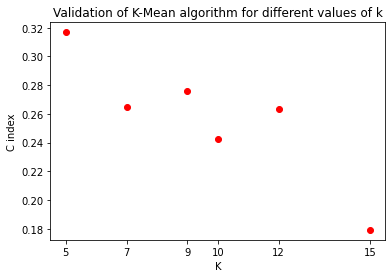

In [23]:
plt.title("Validation of K-Mean algorithm for different values of k")
plt.plot(k_list,C_index_list,'ro')
plt.xlabel("K")
plt.ylabel("C index")
plt.xticks(k_list)
plt.show
plt.savefig('/content/drive/MyDrive/Google colab/C_index.png')

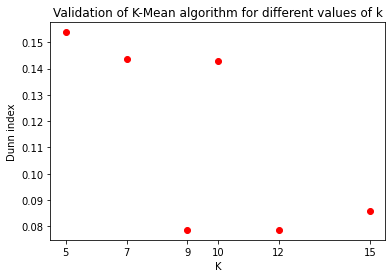

In [24]:
plt.title("Validation of K-Mean algorithm for different values of k")
plt.plot(k_list,D_index_list,'ro')
plt.xlabel("K")
plt.ylabel("Dunn index")
plt.xticks(k_list)
plt.show
plt.savefig('/content/drive/MyDrive/Google colab/Dunn_index.png')

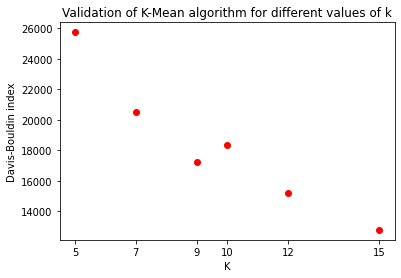

In [25]:
plt.title("Validation of K-Mean algorithm for different values of k")
plt.plot(k_list,DB_index_list,'ro')
plt.xlabel("K")
plt.ylabel("Davis-Bouldin index")
plt.xticks(k_list)
plt.show
plt.savefig('/content/drive/MyDrive/Google colab/DB_index.png')